# Реализовать преобразование Хаара (3 ступени сжатия)

In [1]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

In [2]:
def haar_rows(img):
    a = img[:, 0::2]
    b = img[:, 1::2]
    approx = (a + b) / 2
    detail = (a - b) / 2
    return np.concatenate([approx, detail], axis=1)

def haar_2d(img):
    rows = haar_rows(img)
    return haar_rows(rows.T).T

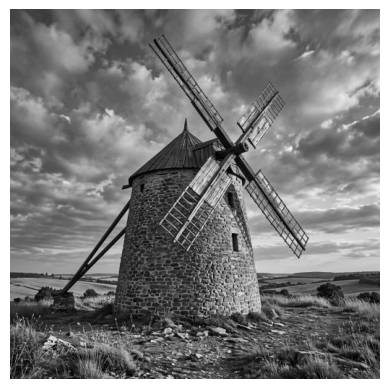

In [3]:
img = cv2.imread("img2.jpeg", cv2.IMREAD_GRAYSCALE)
img = img.astype(np.float64)
plt.axis("off")
plt.imshow(img, cmap="gray")

In [4]:
lvl1 = haar_2d(img)
lvl2 = lvl1.copy()
lvl2[:256, :256] = haar_2d(lvl1[:256, :256])
lvl3 = lvl2.copy()
lvl3[:128, :128] = haar_2d(lvl2[:128, :128])

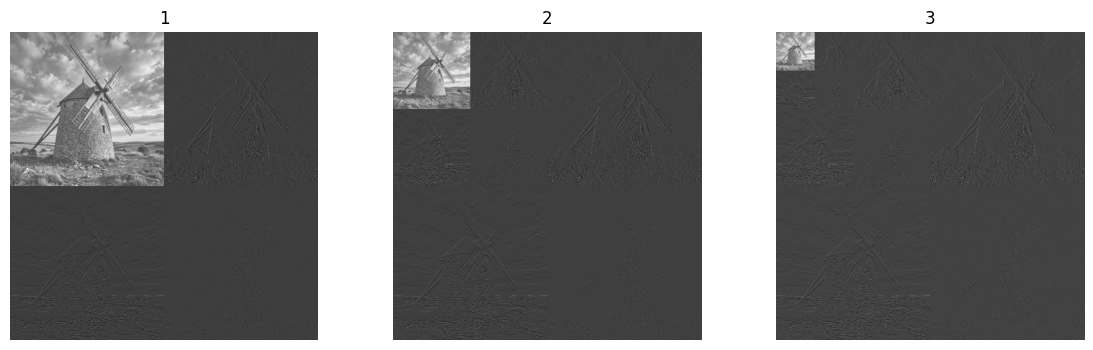

In [5]:
plt.figure(figsize=(14, 4))
plt.subplot(131), plt.imshow(lvl1, cmap="gray"), plt.title("1"), plt.axis("off")
plt.subplot(132), plt.imshow(lvl2, cmap="gray"), plt.title("2"), plt.axis("off")
plt.subplot(133), plt.imshow(lvl3, cmap="gray"), plt.title("3"), plt.axis("off")
plt.show()

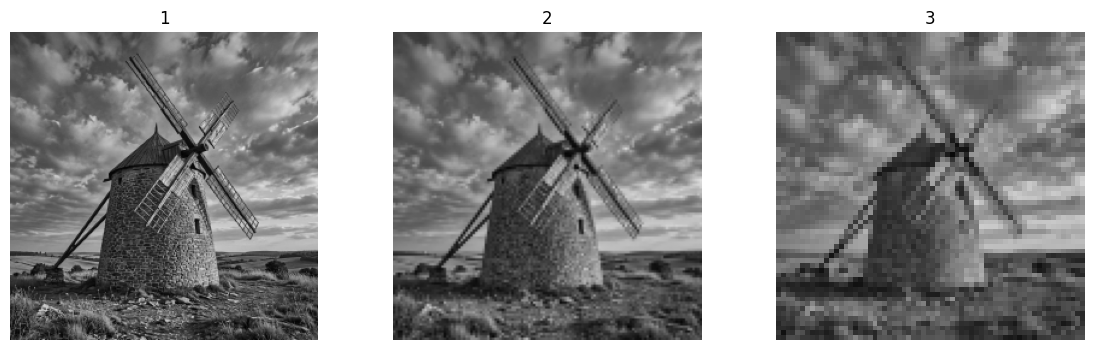

In [6]:
plt.figure(figsize=(14, 4))
plt.subplot(131), plt.imshow(lvl1[:256, :256], cmap="gray", vmin=0, vmax=255), plt.title("1"), plt.axis("off")
plt.subplot(132), plt.imshow(lvl2[:128, :128], cmap="gray", vmin=0, vmax=255), plt.title("2"), plt.axis("off")
plt.subplot(133), plt.imshow(lvl3[:64, :64], cmap="gray", vmin=0, vmax=255), plt.title("3"), plt.axis("off")
plt.show()